# Eyepieces

A telescope or a microscope forms a real image in its focal plane; the
**eyepiece** turns that image into something the eye can look at. Every
point of the focal plane leaves the eyepiece as a parallel beam, and the
directions of these beams make up the **apparent field** the observer sees.
Four numbers describe an eyepiece in use:

- its focal length $f_\mathrm{e}$, which sets the magnifying power
  $M = f_\mathrm{o}/f_\mathrm{e}$ of a telescope with the objective focal
  length $f_\mathrm{o}$,
- the **exit pupil**, the image of the objective formed by the eyepiece, of
  diameter $D' = D/M$, where the observer's eye pupil belongs,
- the **eye relief**, the distance from the last lens to the exit pupil
  (spectacle wearers need 15 to 20 mm),
- the **apparent field** $2\omega'$, the angle the field stop subtends at
  the eye, from 30° to 40° for the oldest designs to 65° and more for wide
  angle eyepieces.

This notebook compares five classical types with `pyoptics.eyepieces`:
the Huygens (1662) and Ramsden (1783) eyepieces of two singlets, the
Kellner (1849) with an achromatic eye lens, the Plössl (1860) of two
doublets and the wide angle Erfle (1917) of five lenses. Its companion,
notebook [172 (binoculars and erecting prisms)](172_binoculars_erecting_prisms.ipynb), puts an eyepiece behind an
objective and a prism erector.

**Eyepieces are designed backwards.** The eye pupil is the aperture stop;
seen from the eye, each field point is a parallel beam that the eyepiece
focuses into the field stop. Traced in that direction, an eyepiece is just
a lens with its object at infinity, its stop in front, and the apparent
field as the field angle (right sketch). The transverse ray errors in the
field stop, divided by $f_\mathrm{e}$, are the angular errors the eye sees.

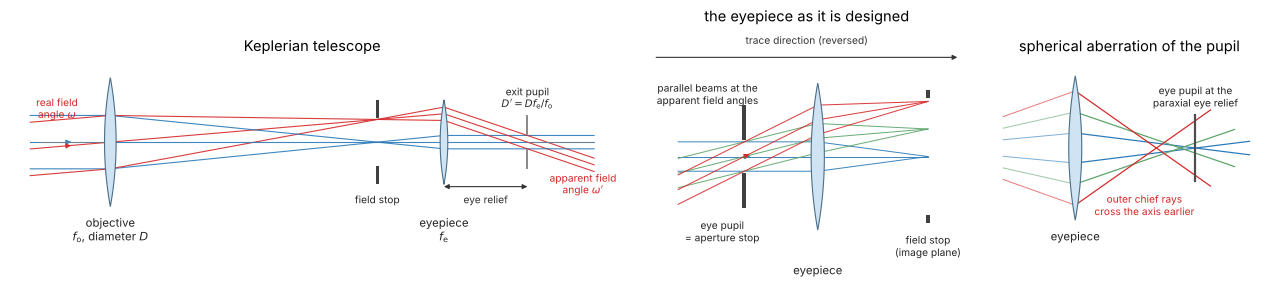

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import eyepieces as ep
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Ramsden": "#e0a000", "Huygens": "#8c6d1f", "Kellner": "#5aa469", "Plössl": "#2a7ab9",
          "Erfle": "#d6604d"}
GREY = "0.45"
t_start = time.time()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw=dict(width_ratios=[2.3, 1.25, 1.0]))
with sketch.text_scale(1.15):
    sketch.eyepiece_layout(ax[0], "telescope", title="Keplerian telescope")
    sketch.eyepiece_layout(ax[1], "reversed", title="the eyepiece as it is designed")
    sketch.eyepiece_layout(ax[2], "pupil", title="spherical aberration of the pupil")
plt.tight_layout(); plt.show()

The right sketch shows a defect that only appears in the forward direction:
the chief rays of the outer field cross the axis closer to the eyepiece
than the paraxial exit pupil. Section 5 comes back to it.

## 1. Five classical eyepieces

`ep.eyepieces()` returns the five designs at $f_\mathrm{e} = 25$ mm (each
also on its own: `ep.huygens()`, `ep.ramsden()`, `ep.kellner()`,
`ep.ploessl()`, `ep.erfle()`). Huygens and Ramsden follow the classical
thin lens rules with real thicknesses; Kellner, Plössl and Erfle were
optimized for pyoptics with damped least squares (notebook
[58 (lens optimization)](58_lens_optimization.ipynb)) from first order layouts, for a 4 mm eye pupil and
their typical apparent fields. They show what each type can do, they are
not copies of particular commercial eyepieces. `Eyepiece.system()` gives
the reversed `raytrace.System`; we draw each with beams at the centre, half
and full apparent field, from the eye pupil (left) to the field stop
(right):

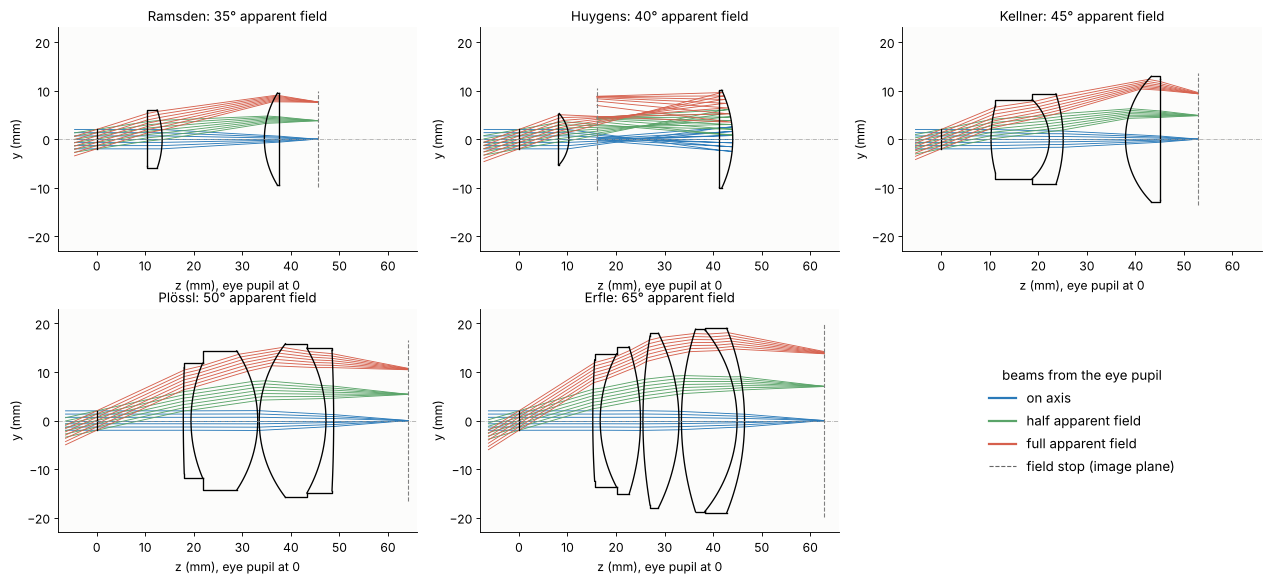

In [2]:
designs = ep.eyepieces()
fig, axes = plt.subplots(2, 3, figsize=(16, 7.2))
colors = ["#2a7ab9", "#5aa469", "#d6604d"]
for e, ax in zip(designs, axes.ravel()):
    s = e.system()
    s.draw(ax, fields=[0.0, 0.5*s.max_field, s.max_field], n_rays=7, colors=colors, lw=0.8)
    ax.set_title("{}: {:.0f}° apparent field".format(e.name, e.apparent_field), fontsize=12)
    # the same scale in all panels, so that the sizes can be compared
    ax.set_aspect("equal", adjustable="box"); ax.set_xlim(-8, 66); ax.set_ylim(-23, 23)
for ax in axes.ravel()[:5]:
    ax.set_xlabel("z (mm), eye pupil at 0"); ax.set_ylabel("y (mm)")
# the free panel explains the colours
leg = axes[1, 2]
leg.axis("off")
for c, label in zip(colors, ("on axis", "half apparent field", "full apparent field")):
    leg.plot([], [], color=c, lw=2, label=label)
leg.plot([], [], color="0.4", ls="--", lw=1, label="field stop (image plane)")
leg.legend(loc="center", fontsize=12, frameon=False, title="beams from the eye pupil",
           title_fontsize=12)
plt.tight_layout(); plt.show()

The Huygens eyepiece is the odd one: its field lens catches the converging
beam of the objective before it comes to a focus, so the field stop sits
*between* the lenses, at the focus of the eye lens (the reversed trace ends
in a virtual image, where the objective alone would focus). All the others
have their field stop in front of the field lens, where a reticle or a
crosshair can sit.

The first order data, in one table:

In [3]:
print("{:8s} {:>7s} {:>11s} {:>15s} {:>13s} {:>8s}".format(
    "type", "f (mm)", "eye relief", "field stop (mm)", "app. field", "lenses"))
for e in designs:
    s = e.system()
    h = s.paraxial().efl*np.tan(np.radians(e.apparent_field/2))
    stop = ep._chief(s, np.radians(e.apparent_field/2))[0][1]  # real chief ray height
    n_lenses = sum(1 for k in e.surfaces if k.material is not None)
    print("{:8s} {:7.1f} {:8.1f} mm {:15.1f} {:11.0f}° {:8d}".format(
        e.name, e.focal_length, e.eye_relief(), 2*stop, e.apparent_field, n_lenses))

type      f (mm)  eye relief field stop (mm)    app. field   lenses
Ramsden     25.0     10.4 mm            15.3          35°        2
Huygens     25.0      8.0 mm            17.2          40°        2
Kellner     25.0     10.3 mm            18.7          45°        3
Plössl      25.0     17.8 mm            21.2          50°        4
Erfle       25.0     15.2 mm            27.9          65°        5


The eye relief here is the distance from the last vertex to the exit pupil
for an objective 250 mm in front of the field stop (a 10× telescope). It
grows from 0.3 $f_\mathrm{e}$ (Huygens) and 0.4 $f_\mathrm{e}$ (Ramsden,
Kellner) to 0.6 $f_\mathrm{e}$ (Erfle) and 0.7 $f_\mathrm{e}$ (Plössl). At
$f_\mathrm{e} = 25$ mm only the Plössl and, just, the Erfle leave room for
spectacles. Eye
relief scales with the focal length, which is why short eyepieces of the
classical types are so uncomfortable, and why modern short eyepieces put
a negative (Barlow or Smyth) group in front.

The field stop diameters are those of the real chief rays at the rim of
the apparent field. For the Erfle it is smaller than $2 f_\mathrm{e}
\tan\omega'$ (31.8 mm): with the negative distortion of the eyepiece
(section 4), a stop of 28 mm already fills 65°. For the Huygens the number
is the size of the objective's image that the field lens intercepts; the
physical field stop, at the focus of the eye lens, is smaller.

## 2. Eye relief and the objective

The exit pupil is the image of the objective. Newton's equation puts it
$f_\mathrm{e}^2/f_\mathrm{o}$ behind the eye-side focal point of the
eyepiece: a short telescope moves the eye point away from the eyepiece.
`Eyepiece.eye_relief(objective_distance)` follows the real thick lenses:

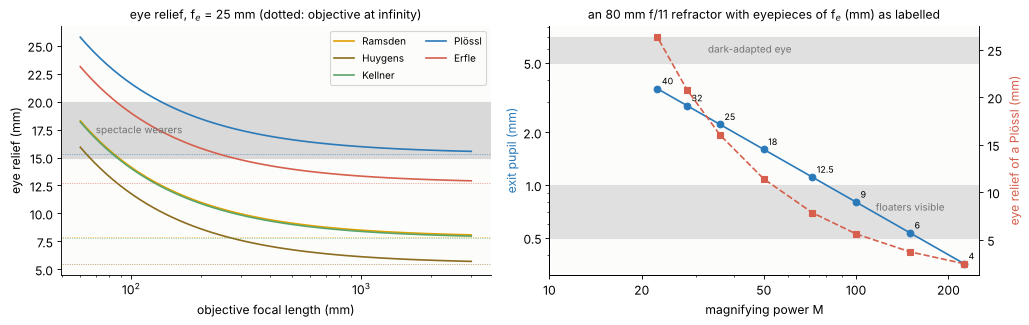

In [4]:
f_obj = np.geomspace(60, 3000, 60)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for e in designs:
    er = [e.eye_relief(L) for L in f_obj]
    ax[0].semilogx(f_obj, er, color=COLORS[e.name], label=e.name)
    ax[0].axhline(e.eye_relief(np.inf), color=COLORS[e.name], lw=0.6, ls=":")
ax[0].axhspan(15, 20, color="0.85", zorder=0)
ax[0].text(70, 17.5, "spectacle wearers", fontsize=9, va="center", color=GREY)
ax[0].set_xlabel("objective focal length (mm)"); ax[0].set_ylabel("eye relief (mm)")
ax[0].set_title("eye relief, f$_e$ = 25 mm (dotted: objective at infinity)", fontsize=11)
ax[0].legend(fontsize=9, ncol=2)

D, f_o = 80.0, 900.0  # an 80 mm f/11 refractor
fe = np.array([4, 6, 9, 12.5, 18, 25, 32, 40])
M = f_o/fe
ax[1].plot(M, D/M, "o-", color="#2a7ab9", label="exit pupil D/M")
ax2 = ax[1].twinx()
ax2.plot(M, [ep.ploessl(f).eye_relief(f_o) for f in fe], "s--", color="#d6604d",
         label="eye relief, Plössl")
ax2.spines["right"].set_visible(True)
ax2.set_ylabel("eye relief of a Plössl (mm)", color="#d6604d")
ax[1].axhspan(0.5, 1.0, color="0.88", zorder=0)
ax[1].axhspan(5, 7, color="0.88", zorder=0)
ax[1].text(150, 0.75, "floaters visible", fontsize=9, ha="center", va="center", color=GREY)
ax[1].text(45, 6, "dark-adapted eye", fontsize=9, ha="center", va="center", color=GREY)
for m_, f in zip(M, fe):
    ax[1].annotate("{:g}".format(f), (m_, D/m_), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
from matplotlib.ticker import ScalarFormatter, NullFormatter
for axis in (ax[1].xaxis, ax[1].yaxis):
    axis.set_major_formatter(ScalarFormatter()); axis.set_minor_formatter(NullFormatter())
ax[1].set_xticks([10, 20, 50, 100, 200]); ax[1].set_yticks([0.5, 1, 2, 5])
ax[1].set_xlabel("magnifying power M"); ax[1].set_ylabel("exit pupil (mm)", color="#2a7ab9")
ax[1].set_title("an 80 mm f/11 refractor with eyepieces of f$_e$ (mm) as labelled", fontsize=11)
plt.tight_layout(); plt.show()

For long telescopes the eye relief settles at the eye-side focal distance
(dotted); a 60 mm objective focal length (a finder or a binocular
eyepiece behind a short objective) adds a few millimetres. On the right, the
classical trade-off at the telescope: a long eyepiece gives a low power and
a large exit pupil (above about 7 mm it is larger than a dark-adapted eye
pupil and the rim of the objective is wasted), a short one a high power, a
tiny exit pupil (below 1 mm floaters in the eye become visible) and an eye
relief that shrinks with $f_\mathrm{e}$.

## 3. Field curvature and astigmatism in diopters

An eyepiece's image surfaces are curved. In the reversed trace they are
focus shifts $\Delta z$ in front of or behind the field stop; for the eye,
a shift $\Delta z$ means that the beam leaving the eyepiece is not parallel
but has the vergence $\Delta z/f_\mathrm{e}^2$. `ep.field_curves()` finds
the tangential and sagittal foci from neighbouring real rays and reports
them in diopters, positive for a diverging beam (a virtual image at a
finite distance, which the eye can accommodate). A young eye accommodates
several diopters, an older one hardly any: the curvature common to both
foci is forgiving, the difference between them (astigmatism) is not.

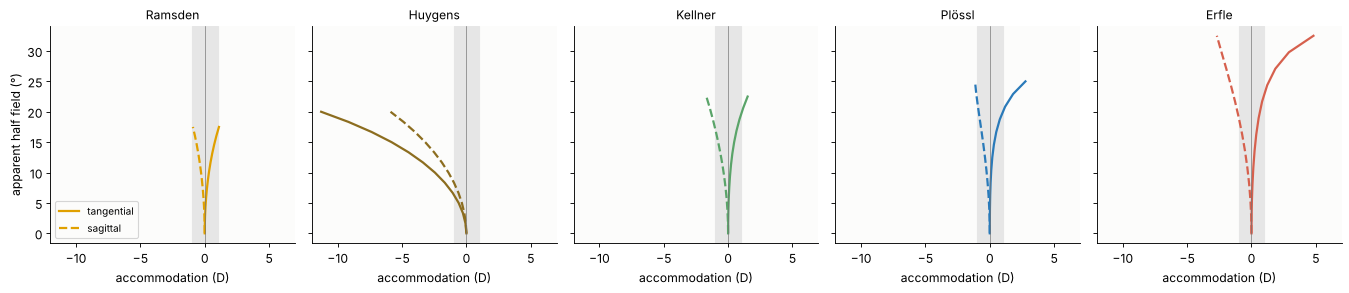

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True)
for e, ax in zip(designs, axes):
    s = e.system()
    th = np.linspace(0, e.apparent_field/2, 13)[1:]
    tan, sag = ep.field_curves(s, th)
    ax.plot(np.r_[0, tan], np.r_[0, th], color=COLORS[e.name], lw=2, label="tangential")
    ax.plot(np.r_[0, sag], np.r_[0, th], color=COLORS[e.name], lw=2, ls="--", label="sagittal")
    ax.axvspan(-1, 1, color="0.9", zorder=0)
    ax.axvline(0, color=GREY, lw=0.6)
    ax.set_xlim(-12, 7); ax.set_xlabel("accommodation (D)")
    ax.set_title(e.name, fontsize=11)
axes[0].set_ylabel("apparent half field (°)")
axes[0].legend(fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

The grey band is ±1 D. The Ramsden, with its small field, stays within
it. The Huygens curves strongly backwards: its rim demands −6 to −11 D,
a converging beam that no eye can focus, which is why its outer field is
soft whatever the observer does. The Kellner keeps both surfaces within about
1.5 D; the Plössl keeps both within 1 D up to about 15° before the
tangential surface turns away to 2.7 D at 25°; the
Erfle splits the difference, −2.5 D sagittal and +5 D tangential at
32°. This astigmatism at the rim, not the sharpness on the axis, is what
separates eyepieces in practice: the eye can accommodate the mean, but
not the difference.

## 4. Lateral colour and distortion

Two aberrations that do not depend on the size of the eye pupil, and so
remain when the pupil is small: **lateral colour** (the F and C images of a
point at the rim are separated, a star becomes a short spectrum) and
**distortion** (`ep.distortion()`: the chief ray height in the field stop
against $f_\mathrm{e}\tan\omega'$).

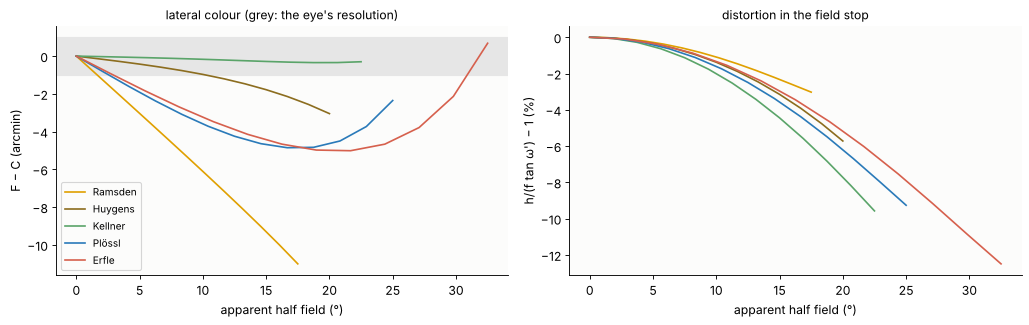

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for e in designs:
    s = e.system()
    th = np.linspace(0, e.apparent_field/2, 13)
    ax[0].plot(th, ep.lateral_colour(s, th), color=COLORS[e.name], label=e.name)
    ax[1].plot(th, 100*ep.distortion(s, th), color=COLORS[e.name], label=e.name)
ax[0].axhspan(-1, 1, color="0.9", zorder=0)
ax[0].set_xlabel("apparent half field (°)"); ax[0].set_ylabel("F − C (arcmin)")
ax[0].set_title("lateral colour (grey: the eye's resolution)", fontsize=11)
ax[1].set_xlabel("apparent half field (°)"); ax[1].set_ylabel("h/(f tan ω') − 1 (%)")
ax[1].set_title("distortion in the field stop", fontsize=11)
ax[0].legend(fontsize=9); plt.tight_layout(); plt.show()

The Ramsden, two singlets of one glass at two thirds of their focal length
apart, has 11 arcmin of lateral colour at the rim, about ten times the
resolution of the eye. Huygens found the cure with the same glass: two
thin lenses of one glass have a focal length independent of the
wavelength if their distance is half the sum of their focal lengths,
$d = (f_1 + f_2)/2$ (here $f_1 = 3f_2$, $d = 2f_2$), and the Huygens
eyepiece stays within 3 arcmin. Kellner replaced the eye lens of the
Ramsden by an achromat and brought the colour below half an arcminute; Plössl
and Erfle balance a few arcmin of colour against their other errors.

All five eyepieces have negative (barrel) distortion in the field stop:
the field stop of radius $h$ subtends a larger angle than
$\arctan(h/f_\mathrm{e})$. In the forward direction that is pincushion
distortion of the tangent; a telescope with such an eyepiece magnifies the
angles towards the rim more than in the centre. An eyepiece free of
distortion in the tangent sense, $h = f\tan\omega'$, makes a panning view
look as if the scene rolled over a globe; one with $h = f\omega'$ (the
"angle condition") does not, so wide angle eyepieces are designed somewhere
in between and 5 to 12 % of distortion at the rim is normal.

## 5. Image quality over the field

`ep.angular_blur()` is the polychromatic RMS angular blur (F, d, C) over
the eye pupil, each field in its best focus (the eye accommodates as it
looks around), relative to the chief ray of the d line, so lateral colour
counts. The eye resolves about 1 arcmin.

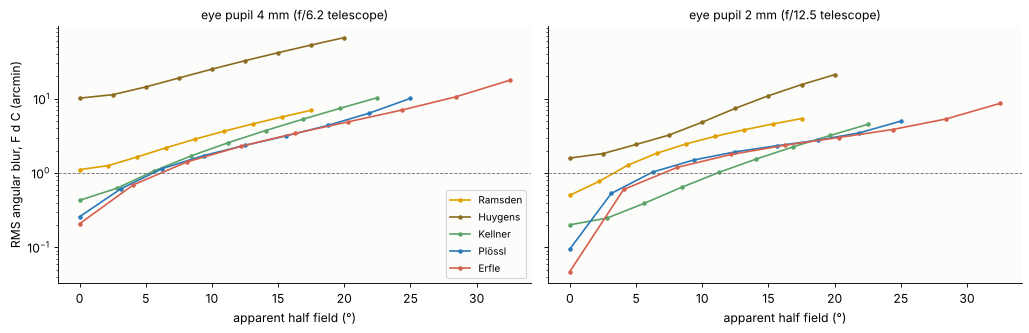

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, pupil in zip(axes, (4.0, 2.0)):
    for e in designs:
        s = e.system(pupil=pupil)
        th = np.linspace(0, e.apparent_field/2, 9)
        ax.plot(th, ep.angular_blur(s, th), "o-", ms=3, color=COLORS[e.name], label=e.name)
    ax.axhline(1.0, color=GREY, lw=0.8, ls="--")
    ax.set_yscale("log"); ax.set_xlabel("apparent half field (°)")
    ax.set_title("eye pupil {:.0f} mm (f/{:.1f} telescope)".format(pupil, 25/pupil), fontsize=11)
axes[0].set_ylabel("RMS angular blur, F d C (arcmin)")
axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

On the axis the Huygens is the only poor eyepiece: its plano-convex eye
lens meets the parallel beam with its flat side, the worst bending for
spherical aberration. With the 4 mm pupil of an f/6 telescope it blurs
the centre by 10 arcmin, with 2 mm still by 1.6; at the f/15 to f/30 of the
long refractors of its time (pupils of 1 mm and less) it was fine, and in
those telescopes it stayed for two centuries. The Ramsden is sharp in the
centre and lost to lateral colour at the rim; the others stay below a
few arcmin out to about two thirds of their field and then rise, mostly
through astigmatism. Halving the pupil halves the astigmatic blur; the
colour stays.

What the eye sees across the field: spot diagrams in arcminutes at the
centre, two thirds and the rim of each field (F blue, d green, C red),
each in its best focus. The axes scale with the spots (note the
numbers), the small circle is 1 arcmin across:

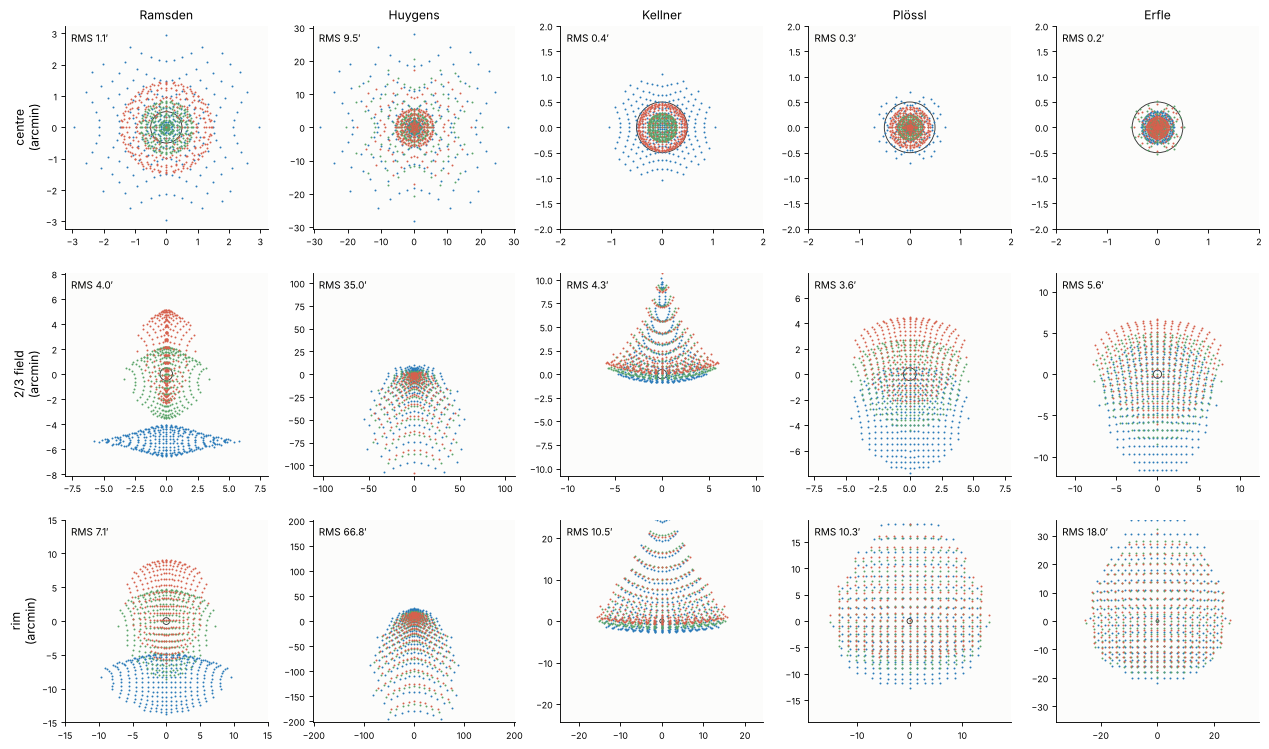

In [8]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9.6))
wl_cols = [("F", "#2a7ab9"), ("d", "#5aa469"), ("C", "#d6604d")]
p = np.linspace(-1, 1, 21)
PX, PY = np.meshgrid(p, p)
inside = PX**2 + PY**2 <= 1
for j, e in enumerate(designs):
    s = e.system()
    f = s.paraxial().efl
    for i, frac in enumerate((0.0, 2/3, 1.0)):
        th = np.radians(frac*e.apparent_field/2)
        I0, d0 = ep._chief(s, th)
        pts = []
        for name, c in wl_cols:
            sw = s.with_wavelength(ep.WAVELENGTHS[name])
            I, d = sw._image_hits(sw.trace_pupil(th, PX[inside], PY[inside], clip=False))
            pts.append((I, d, c))
        allI = np.concatenate([q[0] for q in pts]); alld = np.concatenate([q[1] for q in pts])

        def rms(dz):
            x = allI[:, 0] + dz*alld[:, 0]/alld[:, 2] - I0[0] - dz*d0[0]/d0[2]
            y = allI[:, 1] + dz*alld[:, 1]/alld[:, 2] - I0[1] - dz*d0[1]/d0[2]
            return np.nanmean(x**2 + y**2)
        dzs = np.linspace(-1.5, 1.5, 301)
        dz = dzs[np.argmin([rms(z) for z in dzs])]
        ax = axes[i, j]
        xs, ys = [], []
        for I, d, c in pts:
            x = (I[:, 0] + dz*d[:, 0]/d[:, 2] - I0[0] - dz*d0[0]/d0[2])/f/ep.ARCMIN
            y = (I[:, 1] + dz*d[:, 1]/d[:, 2] - I0[1] - dz*d0[1]/d0[2])/f/ep.ARCMIN
            ax.plot(x, y, ".", ms=1.5, color=c)
            xs.append(x); ys.append(y)
        ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color="0.2", lw=0.8))
        r = np.hypot(np.concatenate(xs), np.concatenate(ys))
        lim = max(2.0, 1.15*np.nanpercentile(r, 98))
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        ax.text(0.03, 0.97, "RMS {:.1f}′".format(np.sqrt(np.nanmean(r**2))), transform=ax.transAxes,
                fontsize=9, va="top")
        ax.tick_params(labelsize=8)
        if i == 0:
            ax.set_title(e.name, fontsize=11)
        if j == 0:
            ax.set_ylabel(["centre", "2/3 field", "rim"][i] + "\n(arcmin)")
plt.tight_layout(); plt.show()

The Ramsden's spots are short spectra (lateral colour: blue, green and red
images side by side), the Huygens's centre is a broad halo of spherical
aberration around a small core. The Kellner's spots are comets (coma with
a little colour), the Plössl's and the Erfle's grow into broad fans of
astigmatism and coma at the rim, the Erfle's at 32° instead of 22° or
25°. The RMS values in the corners are about the radii of the spots; all
three corrected eyepieces stay at or below half an arcminute in the
centre.

## 6. The exit pupil off the axis: kidney beans

The exit pupil of section 2 is the paraxial image of the objective. In a
wide field eyepiece the chief rays of the outer field cross the axis
noticeably closer to the lens (`ep.pupil_aberration()`), the spherical
aberration of the pupil. `ep.telescope()` puts the eyepiece behind a
perfect objective (a 10× telescope with an exit pupil of 4 mm) and traces
in the direction of the light, with the image plane at the eye. The beams
leaving the eyepiece are collimated; where they cross the plane of the eye
pupil shows whether they enter it:

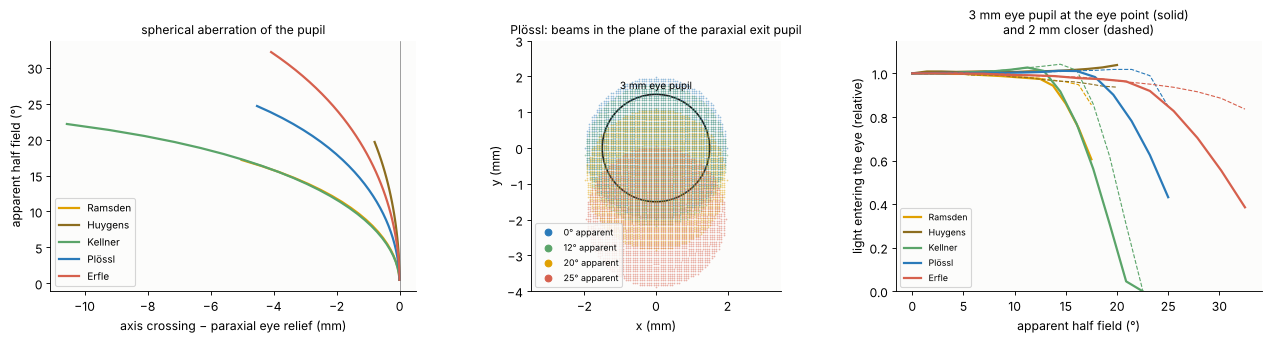

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1.2, 1.1]))
ax = axes[0]
th = np.linspace(0.5, 33, 40)
for e in designs:
    z, ang = ep.pupil_aberration(e, th)
    ok = th <= e.apparent_field/2 + 1e-9
    ax.plot(z[ok] - e.eye_relief(), th[ok], color=COLORS[e.name], lw=2, label=e.name)
ax.axvline(0, color=GREY, lw=0.6)
ax.set_xlabel("axis crossing − paraxial eye relief (mm)"); ax.set_ylabel("apparent half field (°)")
ax.set_title("spherical aberration of the pupil", fontsize=11); ax.legend(fontsize=9)

plo = ep.ploessl()
tel = ep.telescope(plo)
fmax = np.degrees(tel.max_field)
ax = axes[1]
for frac, c in zip((0.0, 0.5, 0.8, 1.0), ("#2a7ab9", "#5aa469", "#e0a000", "#d6604d")):
    x, y = ep.pupil_footprint(tel, frac*fmax, n=61)
    ax.plot(x, y, ".", ms=1, color=c, alpha=0.5)
    ax.plot([], [], "o", color=c, label="{:.0f}° apparent".format(frac*plo.apparent_field/2))
ax.add_patch(plt.Circle((0, 0), 1.5, fill=False, color="0.1", lw=1.5))
ax.text(0, 1.65, "3 mm eye pupil", ha="center", fontsize=9)
ax.set_aspect("equal"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-4.0, 3.0)
ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)")
ax.set_title("Plössl: beams in the plane of the paraxial exit pupil", fontsize=11)
ax.legend(fontsize=8, loc="lower left", markerscale=1)

ax = axes[2]
for e in designs:
    t = ep.telescope(e)
    fm = np.degrees(t.max_field)
    fr = np.linspace(0, 1, 15)
    T0 = ep.eye_transmission(t, fr*fm, 3.0)
    T1 = ep.eye_transmission(t, fr*fm, 3.0, offset=-2.0)
    ax.plot(fr*e.apparent_field/2, T0/T0[0], color=COLORS[e.name], lw=2, label=e.name)
    ax.plot(fr*e.apparent_field/2, T1/T1[0], color=COLORS[e.name], lw=1, ls="--")
ax.set_xlabel("apparent half field (°)"); ax.set_ylabel("light entering the eye (relative)")
ax.set_title("3 mm eye pupil at the eye point (solid)\nand 2 mm closer (dashed)", fontsize=11)
ax.set_ylim(0, 1.15); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

In the middle panel the beam of the field centre (blue) fills a 4 mm disc
centred on the axis; towards the rim the beams drift off the axis in the
plane of the paraxial exit pupil, because they have already crossed it.
An eye pupil of 3 mm (daylight) at the paraxial eye point loses most of
the light of the rim (right panel, solid lines): the outer field darkens,
and with small head movements it blacks out in kidney-shaped patches.
Moving the eye 2 mm closer (dashed) brings back most of the light of the
rim, and the centre does not mind, since the central beam is still
larger than the eye pupil. Observers do this instinctively; designers of modern wide
field eyepieces correct the pupil aberration explicitly, together with
the image errors. The Huygens hardly suffers from it; the Ramsden and the
Kellner, whose strongly curved field lens does much of the pupil
imaging, lose the rim of their smaller fields as quickly as the wide angle
types.

A by-product of `ep.telescope()`: the traced angular magnification grows
from the centre to the rim, the forward view of the distortion of
section 4:

In [10]:
for e in designs:
    t = ep.telescope(e)
    fm = np.degrees(t.max_field)
    m0, m1 = ep.angular_magnification(t, 0.01*fm), ep.angular_magnification(t, fm)
    print("{:8s} tan ω'/tan ω on the axis {:6.2f}, at the rim {:6.2f} ({:+.0f} %)".format(
        e.name, m0, m1, 100*(m1/m0 - 1)))

Ramsden  tan ω'/tan ω on the axis -10.00, at the rim -10.37 (+4 %)
Huygens  tan ω'/tan ω on the axis -10.00, at the rim -10.54 (+5 %)
Kellner  tan ω'/tan ω on the axis -10.00, at the rim -11.17 (+12 %)
Plössl   tan ω'/tan ω on the axis -10.00, at the rim -11.25 (+13 %)
Erfle    tan ω'/tan ω on the axis -10.00, at the rim -11.71 (+17 %)


## Summary

- Eyepieces are designed backwards: the eye pupil is the stop, the
  apparent field the field angle and the field stop the image plane
  (`Eyepiece.system()`); angular errors are transverse errors divided by
  the focal length, focus errors are diopters $\Delta z/f^2$.
- The eye relief is set by the type and scales with the focal length:
  0.3 $f$ for the Huygens up to 0.7 $f$ for the Plössl; the exit pupil
  is $D/M$ (`Eyepiece.eye_relief()`, `ep.telescope()`).
- Huygens: lateral colour corrected with one glass, poor on the axis at
  large pupils. Ramsden: sharp, but uncorrected lateral colour. Kellner:
  achromatic eye lens, colour gone, astigmatism at the rim. Plössl: long
  eye relief and good correction to about 40°. Erfle: 65° at the price of
  five lenses and more distortion.
- Wide field eyepieces suffer from spherical aberration of the pupil: the
  outer beams cross the axis early and miss a small eye pupil (kidney
  beans).

Notebook [172 (binoculars and erecting prisms)](172_binoculars_erecting_prisms.ipynb) turns the eyepiece around again
and puts it into a binocular.

## References

- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed.,
  Academic Press (2010), chapter 14.
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008),
  chapter 13.
- H. Rutten and M. van Venrooij, *Telescope Optics: Evaluation and
  Design*, Willmann-Bell (1988), chapters 21 to 23.
- H. Dennis Taylor, *A System of Applied Optics*, Macmillan (1906).

In [11]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 6 s
